In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import warnings
warnings.filterwarnings('ignore')

def housing_data_reader(filename='normalized_diabetes.csv'):
    data = pd.read_csv(filename)
    X = data.drop(['diabetes'],axis = 1)
    y = data['diabetes']
    return X, y

In [2]:
from sklearn.model_selection import train_test_split
# import lightgbm as lgb
from sklearn.metrics import r2_score,f1_score
# define the characteristic function
def classification_kpi(G,S):
    """_summary_

    Args:
        G (nx.Graph): _description_
        S (list): list of nodes (list of columns)
    """
    cols = list(S)
    if len(cols) == 0:
        return 0
    else:
        x_train, x_test, y_train, y_test = train_test_split(X[cols], y, test_size=0.2, random_state=42)
        model = Sequential()
        model.add(Dense(64, input_dim=x_train.shape[1], activation='relu'))  # 输入层和第一个隐藏层
        model.add(Dense(64, input_dim=x_train.shape[1], activation='relu'))
        model.add(Dense(32, activation='relu'))  # 第三个隐藏层
        model.add(Dense(1, activation='sigmoid'))   # 输出层

# 编译模型
        model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# 训练模型
        model.fit(x_train, y_train, epochs=10, batch_size=10, validation_split=0.2, verbose=0)
        y_pred = model.predict(x_test)
        # y_pred_classes = (y_pred > 0.5).astype("int32")
        f1 = f1_score(y_test, y_pred.round())
        return f1

In [3]:
import networkx as nx
import shapG.shapley as shapley
import shapG.plot as shapGplot
from shapG.utils import corr_generator, create_minimal_edge_graph
import time

In [4]:
s = time.time()

In [5]:
# explain the model
X, y = housing_data_reader('normalized_diabetes.csv')
W = corr_generator(X)
A, W_new = create_minimal_edge_graph(W, version='v3')
G = nx.Graph(A)
shapley_value = shapley.shapG(G, m=3, f=classification_kpi, approximate_by_ratio=False)

  0%|                                                    | 0/17 [00:00<?, ?it/s]

27/27 [==============================] - 0s 259us/step


  6%|██▍                                      | 1/17 [05:37<1:29:57, 337.32s/it]

27/27 [==============================] - 0s 262us/step


 12%|████▊                                    | 2/17 [11:16<1:24:35, 338.36s/it]

...

 88%|███████████████████████████████████▎    | 15/17 [1:30:51<11:01, 330.78s/it]

27/27 [==============================] - 0s 270us/step


 94%|█████████████████████████████████████▋  | 16/17 [1:35:31<05:15, 315.47s/it]

27/27 [==============================] - 0s 245us/step


100%|████████████████████████████████████████| 17/17 [1:35:36<00:00, 337.43s/it]


In [6]:
e = time.time()
e-s

5736.587858200073

In [7]:
sorted_data = sorted(shapley_value.items(), key=lambda x: x[1])

sorted_data

[('Chol', -0.014957965308319832),
 ('ALT', -0.009432982670893014),
 ('family_histroy', 0.0),
 ('BUN', 0.015933134506325233),
 ('CCR', 0.034117741531562974),
 ('Gender', 0.04332139522034668),
 ('DBP', 0.10065151961384569),
 ('BMI', 0.10788685959023478),
 ('Tri', 0.15672182394887346),
 ('SBP', 0.4302212339268999),
 ('LDL', 0.6332980718240645),
 ('Age', 0.7030577851878803),
 ('drinking', 0.7570369240644075),
 ('HDL', 0.766002992728199),
 ('smoking', 0.769373759828738),
 ('FPG', 0.9879978794365848),
 ('FFPG', 1.294401151649507)]

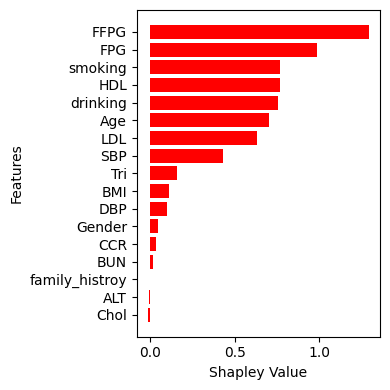

In [13]:
import matplotlib.pyplot as plt

# 提取特征名称和权重（按权重从大到小排序）
data = [('Chol', -0.014957965308319832),
 ('ALT', -0.009432982670893014),
 ('family_histroy', 0.0),
 ('BUN', 0.015933134506325233),
 ('CCR', 0.034117741531562974),
 ('Gender', 0.04332139522034668),
 ('DBP', 0.10065151961384569),
 ('BMI', 0.10788685959023478),
 ('Tri', 0.15672182394887346),
 ('SBP', 0.4302212339268999),
 ('LDL', 0.6332980718240645),
 ('Age', 0.7030577851878803),
 ('drinking', 0.7570369240644075),
 ('HDL', 0.766002992728199),
 ('smoking', 0.769373759828738),
 ('FPG', 0.9879978794365848),
 ('FFPG', 1.294401151649507)]

labels, values = zip(*data)

plt.figure(figsize=(4, 4))

# 使用Matplotlib的barh()函数绘制条形图
plt.barh(labels, values, color='r')

plt.xlabel('Shapley Value')
plt.ylabel('Features')

# 使用tight_layout来调整图表以适应指定的图形大小
plt.tight_layout()

# 保存图像，确保DPI设置为300，并包括标签和边距
plt.savefig('shapG_diabetes_nn.eps', format='eps', dpi=300, bbox_inches='tight')

plt.show()


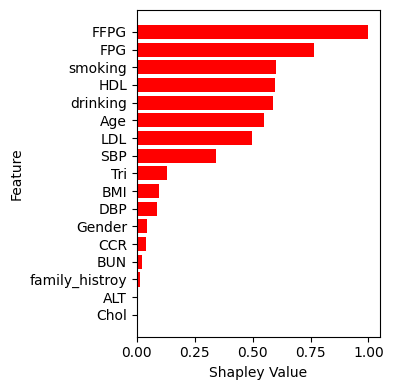

In [1]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import numpy as np

data = [('Chol', -0.014957965308319832),
 ('ALT', -0.009432982670893014),
 ('family_histroy', 0.0),
 ('BUN', 0.015933134506325233),
 ('CCR', 0.034117741531562974),
 ('Gender', 0.04332139522034668),
 ('DBP', 0.10065151961384569),
 ('BMI', 0.10788685959023478),
 ('Tri', 0.15672182394887346),
 ('SBP', 0.4302212339268999),
 ('LDL', 0.6332980718240645),
 ('Age', 0.7030577851878803),
 ('drinking', 0.7570369240644075),
 ('HDL', 0.766002992728199),
 ('smoking', 0.769373759828738),
 ('FPG', 0.9879978794365848),
 ('FFPG', 1.294401151649507)]

labels, values = zip(*data)

values = np.array(values).reshape(-1, 1)

# 使用MinMaxScaler进行归一化
scaler = MinMaxScaler()
normalized_values = scaler.fit_transform(values).flatten()

# 绘制条形图
plt.figure(figsize=(4, 4))

# 使用Matplotlib的barh()函数绘制条形图
plt.barh(labels, normalized_values, color='r')

plt.xlabel('Shapley Value')
plt.ylabel('Feature')

# 使用tight_layout来调整图表以适应指定的图形大小
plt.tight_layout()

# 保存图像，确保DPI设置为300，并包括标签和边距
plt.savefig('shapG_diabetes_nn_normalized.eps', format='eps', dpi=300, bbox_inches='tight')

plt.show()